# 8.4 — Logistic Regression

**Chapter 8, section 8.3.1**, and the starting point for **Exercise 6** and **Exercise 10**.

**The question this notebook answers:** how much of the distributed machinery has to change when
the model changes from regression to classification?

The answer is: the arithmetic inside the `map`, and nothing else. The gradient of the logistic
loss has the same shape as the gradient of the squared-error loss — a feature vector multiplied by
a scalar residual, summed over the examples — so the `map`, the aggregation, and the driver-side
update are all reusable without modification. Only the definition of the residual changes, from
$y_i - \theta^T x_i$ to $\sigma(\theta_i) - y_i$.

The notebook writes the same training loop three times: with `map` and `reduce`, with the
exponential computed once, and with `treeAggregate`. It then evaluates the classifier on held-out
data, compares it against linear regression used as a classifier, and finishes with the
`pyspark.ml` estimator that does all of this in two lines.

Source: `Notebooks old/Spark-Example-19-Logistic-Regression.ipynb`.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.4")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. The model

In logistic regression the response is a Bernoulli random variable — a binary outcome — whose
probability mass function is

$$P(Y = y) = \begin{cases} p & \text{if } y = 1 \\ 1-p & \text{if } y = 0 \end{cases}$$

or, written as one expression rather than two cases,

$$
p(y \mid p) = p^y (1-p)^{1-y}.
$$

Put into exponential-family form this becomes

$$
p(y \mid \theta) = \exp\left(y \theta - \log(1+e^\theta)\right),
\qquad \theta = \log\frac{p}{1-p}, \qquad p = \frac{1}{1+e^{-\theta}}
$$

where $\theta$ is the **log-odds** of the positive class. The log-odds is unconstrained — it
ranges over the whole real line — which is exactly what makes it safe to model as a linear
combination of the features, $\theta = x^T \beta$. The predicted probability comes back by
applying the sigmoid, $\sigma(z) = 1/(1+e^{-z})$, which maps every real number into $(0,1)$.

The parameters are estimated by maximizing the log-likelihood

$$
\mathrm{LLH}(\beta) = \sum_{i=1}^{n}\left(y_i\theta_i - \log(1+e^{\theta_i})\right),
\qquad \theta_i = x_i^T \beta,
$$

which, multiplied by $-1$ so that gradient *descent* applies, is the loss this notebook minimizes.

Differentiating gives the gradient

$$
\frac{\partial L}{\partial \beta_j} = \sum_{i=1}^{n} x_{ij}\left(\sigma(\theta_i) - y_i\right),
$$

that is, each example's feature vector scaled by the gap between the probability the model
currently predicts and the label actually observed. Examples the model already gets right
contribute almost nothing; examples it gets confidently wrong contribute a lot.

---

## 2. The data

Two Gaussian blobs in two dimensions, fifty thousand points each. The classes are close to
linearly separable, which keeps the attention on the optimization rather than on the difficulty of
the problem.

In [2]:
from sklearn.datasets import make_blobs
import pandas as pd
import matplotlib.cm as cm

n = 100000                                   # total number of samples
ratio_positive = 0.5                         # the class ratio
n_samples = [int(n * (1 - ratio_positive)), int(n * ratio_positive)]

X, y = make_blobs(n_samples=n_samples, centers=None, n_features=2,
                  cluster_std=1.5, random_state=2)

print("class counts:", np.bincount(y))

class counts: [50000 50000]


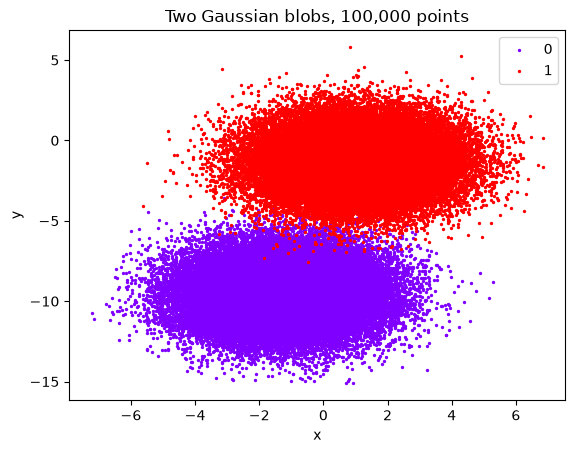

In [3]:
df = pd.DataFrame(dict(x=X[:, 0], y=X[:, 1], label=y))
colors = dict(zip(sorted(set(y)), cm.rainbow(np.linspace(0, 1, len(set(y))))))
fig, ax = plt.subplots()
for key, group in df.groupby('label'):
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key,
               color=colors[key].reshape(1, -1), s=2)
plt.title('Two Gaussian blobs, 100,000 points')
plt.show()

The features and the labels go into RDDs, are zipped into `(label, feature_vector)` pairs, and are
split into training and test sets. Three things about the preparation matter.

* Every record has the shape used throughout this chapter: a label and a NumPy array.
* A constant $1$ is appended to every feature vector, so the intercept is estimated by the same
  update rule as the other coefficients.
* The training RDD is **cached**, and its size is computed **once** and kept on the driver. Asking
  for `count()` inside the loop would launch an extra Spark job on every iteration.

In [4]:
rdd_X = sc.parallelize(X)
rdd_y = sc.parallelize(y)

traindata, testdata = rdd_y.zip(rdd_X).randomSplit([0.8, 0.2], seed=12345)
traindata = traindata.map(lambda x: (x[0], np.append(x[1], 1)))   # fold in the intercept
traindata.cache()
train_size = traindata.count()

print("training examples:", train_size)
traindata.take(3)

training examples: 79966


[(np.int64(0), array([-3.02457665, -9.92809418,  1.        ])),
 (np.int64(0), array([-0.63099809, -8.30119281,  1.        ])),
 (np.int64(0), array([ -0.86104732, -10.42137477,   1.        ]))]

---

## 3. The training loop, with `map` and `reduce`

Each example contributes two quantities to the reduction: its gradient contribution, the feature
vector scaled by $\sigma(\theta_i) - y_i$, and its contribution to the negative log-likelihood.
The `reduce` adds both componentwise, and the driver divides by the count afterwards.

`beta` starts at all ones rather than all zeros here. Both converge to the same place — the
objective is convex — but the starting point changes how many iterations it takes to get there,
which section 5 makes visible.

In [5]:
learningRate = 1
num_iteration = 10

d_input = len(traindata.first()[1])
beta = np.ones(d_input)   # initialize beta; ones are better than zeros for this case
print(f"Input dimensionality is {d_input} and we start with {beta} as parameters")

for i in range(num_iteration):
    gradientAndCost = traindata.map(
        lambda x: (x[1] * (-x[0] + np.exp(np.dot(x[1], beta)) / (1 + np.exp(np.dot(x[1], beta)))),
                   -x[0] * np.dot(x[1], beta) + np.log(1 + np.exp(np.dot(x[1], beta)))))\
        .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / float(train_size)
    gradient = (1 / float(train_size)) * gradientAndCost[0]
    beta = beta - learningRate * gradient
    print(f"{i} Cost:{cost:.5f} Beta {beta}")

# Keep these parameters; the test-set evaluation below uses them.
parameter_vector_sgd = beta

Input dimensionality is 3 and we start with [1. 1. 1.] as parameters
0 Cost:0.39160 Beta [1.0429221  0.58716589 1.19838395]


1 Cost:0.22464 Beta [1.02016161 0.38197592 1.32814456]
2 Cost:0.19442 Beta [0.97361464 0.49095442 1.40174281]
3 Cost:0.18535 Beta [0.94215817 0.41515619 1.49995406]


4 Cost:0.17562 Beta [0.9051854  0.49588619 1.57076375]
5 Cost:0.16795 Beta [0.87865773 0.44529625 1.65856671]
6 Cost:0.16042 Beta [0.84961117 0.50485266 1.72638797]


7 Cost:0.15398 Beta [0.82771925 0.47342481 1.8054695 ]
8 Cost:0.14792 Beta [0.80505573 0.51593336 1.87042858]
9 Cost:0.14251 Beta [0.78717203 0.49946261 1.9420866 ]


---

## 4. The same loop, with the exponential computed once

The loop above evaluates $e^{x_i^T\beta}$ **three times** for every example — twice in the
gradient term and once in the loss. An exponential is far more expensive than an addition or a
multiplication, so this is worth eliminating: a first `map` computes it once, a second consumes
it.

Spark pipelines the two narrow transformations into a single stage, so nothing is materialized in
between and no communication is added. The result is arithmetically identical, and the cell after
this one checks that rather than asserting it.

In [6]:
learningRate = 1
num_iteration = 10

d_input = len(traindata.first()[1])
beta = np.ones(d_input)

for i in range(num_iteration):
    gradientAndCost = traindata.map(lambda x: (x[0], x[1], np.exp(np.dot(x[1], beta))))\
        .map(lambda x: (x[1] * (-x[0] + x[2] / (1 + x[2])),
                        -x[0] * np.dot(x[1], beta) + np.log(1 + x[2])))\
        .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / float(train_size)
    gradient = (1 / float(train_size)) * gradientAndCost[0]
    beta = beta - learningRate * gradient
    print(f"{i} Cost:{cost:.5f} Beta {beta}")

parameter_vector_fast = beta

0 Cost:0.39160 Beta [1.0429221  0.58716589 1.19838395]
1 Cost:0.22464 Beta [1.02016161 0.38197592 1.32814456]
2 Cost:0.19442 Beta [0.97361464 0.49095442 1.40174281]
3 Cost:0.18535 Beta [0.94215817 0.41515619 1.49995406]


4 Cost:0.17562 Beta [0.9051854  0.49588619 1.57076375]
5 Cost:0.16795 Beta [0.87865773 0.44529625 1.65856671]
6 Cost:0.16042 Beta [0.84961117 0.50485266 1.72638797]
7 Cost:0.15398 Beta [0.82771925 0.47342481 1.8054695 ]


8 Cost:0.14792 Beta [0.80505573 0.51593336 1.87042858]
9 Cost:0.14251 Beta [0.78717203 0.49946261 1.9420866 ]


In [7]:
assert np.allclose(parameter_vector_sgd, parameter_vector_fast), \
    "eliminating the repeated exponential must not change the answer"
print("Both loops reach the same parameters:", parameter_vector_fast)

Both loops reach the same parameters: [0.78717203 0.49946261 1.9420866 ]


---

## 5. The same loop, with `treeAggregate`

`reduce` returns one partial result **per partition to the driver**, which then combines them all.
With a handful of partitions and three parameters that is free. With hundreds of partitions and
thousands of parameters the driver becomes a bottleneck, because every partition ships it a full
gradient vector.

`treeAggregate` combines the partial results hierarchically **on the executors** and sends the
driver a single accumulator. Its arguments are the zero value, a `seqOp` that folds one record
into an accumulator, and a `combOp` that merges two accumulators. Because `combOp` here is plain
componentwise addition it is associative, which is what allows the merge to happen in any tree
shape without changing the answer. Spark's own estimators expose the depth of that tree as
`aggregationDepth`, which defaults to 2.

This version also starts from **zeros** rather than ones, which is worth watching in the printed
trace.

In [8]:
learningRate = 1
num_iteration = 10

d_input = len(traindata.first()[1])
beta = np.zeros(d_input)
print(f"Input dimensionality is {d_input} and we start with {beta} as parameters")

for i in range(num_iteration):
    gradientAndCost = traindata.map(lambda x: (x[0], x[1], np.dot(x[1], beta)))\
            .treeAggregate(
              (np.zeros(d_input), 0),
              lambda x, y: (x[0] + y[1] * (-y[0] + np.exp(y[2]) / (1 + np.exp(y[2]))),
                            x[1] - y[0] * y[2] + np.log(1 + np.exp(y[2]))),
              lambda x, y: (x[0] + y[0], x[1] + y[1])
             )
    cost = gradientAndCost[1] / train_size
    gradient = (1 / float(train_size)) * gradientAndCost[0]
    beta = beta - learningRate * gradient
    print(f"{i} Cost:{cost:.5f} Beta {beta}")

parameter_vector_tree = beta

Input dimensionality is 3 and we start with [0. 0. 0.] as parameters


0 Cost:0.69315 Beta [ 5.72522392e-01  2.04608941e+00 -1.25053148e-05]
1 Cost:1.36148 Beta [0.87481332 1.36916801 0.35887264]


2 Cost:0.74398 Beta [1.03478494 0.79835806 0.64482873]
3 Cost:0.38041 Beta [1.06518874 0.4131607  0.84455317]
4 Cost:0.24372 Beta [1.0298284  0.33099144 0.96729502]


5 Cost:0.22984 Beta [0.98509173 0.44565112 1.05622708]
6 Cost:0.21877 Beta [0.95681946 0.35528429 1.17157051]


7 Cost:0.20677 Beta [0.9192656  0.47201569 1.25150949]
8 Cost:0.19773 Beta [0.89657139 0.38210789 1.3588492 ]
9 Cost:0.18735 Beta [0.86566983 0.49110518 1.43201871]


Starting from zeros, the model initially assigns probability exactly one half to every observation,
so the initial negative log-likelihood is $\log 2 \approx 0.69315$ — and the first printed cost is
that number, not a property of the data. The first update then overshoots and the objective
**rises** before settling into a steady decrease.

Both initializations reach essentially the same solution, because the objective is convex and has
one minimum. What the starting point changes is how many iterations it takes to get near it. Ones
happen to be a better guess for this dataset than zeros, which is why section 3 uses them.

---

## 6. Evaluating the classifier

A classifier is judged on data it was not fitted to. Four counts summarize the comparison of
predicted labels against true ones:

* **True positive** ($TP$) — a positive example classified positive.
* **True negative** ($TN$) — a negative example classified negative.
* **False positive** ($FP$) — a negative example classified positive.
* **False negative** ($FN$) — a positive example classified negative.

Together they form the **confusion matrix**, from which the usual metrics follow:

$$ \text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \qquad
   \text{precision} = \frac{TP}{TP + FP}, \qquad
   \text{recall} = \frac{TP}{TP + FN} $$

and the $F_1$ score, the harmonic mean of precision and recall.

The decision rule is the **sign of the linear predictor**. Because $\theta = 0$ is exactly where
the predicted probability is $0.5$, testing `np.dot(x, beta) > 0` is the same rule as thresholding
the probability at one half — which is what `LogisticRegression`'s default `threshold=0.5` does.

In [9]:
testdata1 = testdata.map(lambda x: (x[0], np.append(x[1], 1)))
testdata1.cache()
test_num = testdata1.count()
print("test examples:", test_num, " positives:", testdata1.filter(lambda r: r[0] == 1).count())

test examples: 20034  positives: 10018


The four counts, computed the direct way — one `map` and one `reduce` per cell of the matrix.

In [10]:
predictions = testdata1.map(lambda x: (x[0], 1 if np.dot(x[1], parameter_vector_sgd) > 0 else 0))

true_positive  = predictions.map(lambda x: 1 if (x[0] == 1) and (x[1] == 1) else 0).reduce(lambda x, y: x + y)
false_positive = predictions.map(lambda x: 1 if (x[0] == 0) and (x[1] == 1) else 0).reduce(lambda x, y: x + y)
true_negative  = predictions.map(lambda x: 1 if (x[0] == 0) and (x[1] == 0) else 0).reduce(lambda x, y: x + y)
false_negative = predictions.map(lambda x: 1 if (x[0] == 1) and (x[1] == 0) else 0).reduce(lambda x, y: x + y)

print("--Contingency matrix--")
print(f" TP:{true_positive:6}  FP:{false_positive:6}")
print(f" FN:{false_negative:6}  TN:{true_negative:6}")
print("----------------------")

accuracy = (true_positive + true_negative) / test_num
f1 = true_positive / (true_positive + 0.5 * (false_positive + false_negative))
print(f"Accuracy = {accuracy}  \nF1 = {f1}")

--Contingency matrix--
 TP:  9344  FP:    22
 FN:   674  TN:  9994
----------------------
Accuracy = 0.9652590595986822  
F1 = 0.9640940982253405


That is four Spark actions, so **four jobs and four complete scans of the test set**, and because
`predictions` is not cached the classifier is evaluated four times over as well. One
`treeAggregate` with a four-element accumulator would do the whole thing in one pass. It is
written the long way here because it makes the correspondence between each reduction and each cell
of the matrix immediately visible — and rewriting it as a single pass is **Exercise 6**.

The rest of the notebook needs the same four counts twice more, so they go into a function. It
uses the same four reductions; only the repetition is removed.

In [11]:
def contingency(params, threshold=0.0, data=None):
    # Print the confusion matrix for a linear scorer; return (TP, FP, TN, FN, acc, f1).
    data = testdata1 if data is None else data
    preds = data.map(lambda x: (x[0], 1 if np.dot(x[1], params) > threshold else 0)).cache()
    tp = preds.map(lambda x: 1 if (x[0] == 1) and (x[1] == 1) else 0).reduce(lambda a, b: a + b)
    fp = preds.map(lambda x: 1 if (x[0] == 0) and (x[1] == 1) else 0).reduce(lambda a, b: a + b)
    tn = preds.map(lambda x: 1 if (x[0] == 0) and (x[1] == 0) else 0).reduce(lambda a, b: a + b)
    fn = preds.map(lambda x: 1 if (x[0] == 1) and (x[1] == 0) else 0).reduce(lambda a, b: a + b)
    preds.unpersist()
    acc = (tp + tn) / (tp + tn + fp + fn)
    f1 = tp / (tp + 0.5 * (fp + fn))
    print("--Contingency matrix--")
    print(f" TP:{tp:6}  FP:{fp:6}")
    print(f" FN:{fn:6}  TN:{tn:6}")
    print("----------------------")
    print(f"Accuracy = {acc}  \nF1 = {f1}")
    return tp, fp, tn, fn, acc, f1


_ = contingency(parameter_vector_tree)

--Contingency matrix--
 TP:  8665  FP:    11
 FN:  1353  TN: 10005
----------------------
Accuracy = 0.931915743236498  
F1 = 0.9270354124317963


The confusion matrix says considerably more than the accuracy does. Read the two off-diagonal
counts against each other: this classifier makes far more false negatives than false positives, so
it is **conservative about predicting the positive class** — when it says positive it is usually
right, but it misses a substantial number of true positives.

That imbalance is a property of where the decision threshold sits, not of the learning algorithm.
Moving the threshold away from $0.5$ trades one error type for the other, and the ROC curve and
its area summarize that trade-off across every threshold at once. Section 8.5 takes up what
happens when the *classes* rather than the threshold are unbalanced.

---

## 7. Linear regression used as a classifier

Linear regression is not a classifier, but nothing stops one thresholding its output. It is worth
doing once, because seeing it work badly is the concrete form of the argument at the start of
§8.3.1: a linear fit to $\{0,1\}$ labels is not constrained to $[0,1]$ and its output is not a
probability.

This is the squared-error loop from 8.2 verbatim, on the classification data, with the prediction
thresholded at $0.5$ instead of $0$ — because a linear regression fitted to labels $0$ and $1$
predicts values around those, not log-odds around zero.

In [12]:
learningRate = 0.04
num_iteration = 150

d_input = len(traindata.first()[1])
beta = np.zeros(d_input)
print(f"Input dimensionality is {d_input} and we start with {beta} as parameters")

for i in range(num_iteration):
    gradientAndCost = traindata.map(lambda x: (x[1], (x[0] - np.dot(x[1], beta))))\
                               .map(lambda x: (x[0] * x[1], x[1]**2))\
                               .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / train_size
    gradient = (-1 / float(train_size)) * gradientAndCost[0]
    beta = beta - learningRate * gradient
    if i % 15 == 0 or i == num_iteration - 1:
        print(f"{i} Cost:{cost:.5f} Beta {beta}")

parameter_vector_lin_reg = beta

Input dimensionality is 3 and we start with [0. 0. 0.] as parameters


0 Cost:0.49999 Beta [ 0.02010428 -0.02602445  0.0199995 ]


15 Cost:0.25892 Beta [0.15018598 0.00153248 0.21558626]


30 Cost:0.18462 Beta [0.14647598 0.00422243 0.36084899]


45 Cost:0.13569 Beta [0.13011276 0.02837705 0.476323  ]


...

90 Cost:0.06311 Beta [0.08656428 0.05609218 0.71993737]


105 Cost:0.05212 Beta [0.07684805 0.06520436 0.77510537]


120 Cost:0.04453 Beta [0.06846035 0.07019937 0.82126315]


135 Cost:0.03929 Beta [0.0616902  0.07605998 0.85944944]


149 Cost:0.03587 Beta [0.05632297 0.0799481  0.88933683]


In [13]:
_ = contingency(parameter_vector_lin_reg, threshold=0.5)

--Contingency matrix--
 TP:  9903  FP:    17
 FN:   115  TN:  9999
----------------------
Accuracy = 0.9934112009583708  
F1 = 0.9933794763767679


Read that matrix carefully, because the obvious reading of it is wrong. The thresholded linear
model scores **better** here than the logistic model did above — but it ran for 150 iterations
against the logistic model's 10, so this is a well-trained linear fit against an under-trained
logistic one, and the comparison says nothing about which loss is better. On data this close to
linearly separable, almost any line in roughly the right place will separate most of the points.

What the exercise does establish is the objection that opened §8.3.1, and it survives the good
confusion matrix. The numbers this model produces are **not probabilities**: nothing constrains
them to $[0,1]$, and the threshold of $0.5$ is a convention rather than the point where the two
classes become equally likely. The squared-error loss also spends effort where classification does
not need it — a point predicted at $1.4$ when its label is $1$ contributes a loss, though the
classification is right and confident. The logistic loss has neither defect, which is why it is
the loss for this problem even where thresholding happens to work.

---

## 8. The library's route to the same model

Spark's own `LogisticRegression` does everything above behind one `fit()` call. It does not use
gradient descent: for the dedicated estimator Spark uses **L-BFGS**, a quasi-Newton method,
switching to **OWL-QN** when an $\ell_1$ penalty makes the objective non-smooth. That is why the
estimator has no learning-rate parameter to set — L-BFGS chooses its own step length by line
search along a direction built from the curvature it has estimated.

The cell below fits the estimator on exactly the same data, then lays each of its parameters
against the piece of the hand-written loop it corresponds to. That mapping is **Exercise 10**.

In [14]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.linalg import Vectors

# The estimator manages its own intercept, so the constant column is dropped here.
train_df = traindata.map(lambda r: (float(r[0]), Vectors.dense(r[1][:-1]))).toDF(["label", "features"])
test_df = testdata1.map(lambda r: (float(r[0]), Vectors.dense(r[1][:-1]))).toDF(["label", "features"])
train_df.cache(); train_df.count()

lr = LogisticRegression(featuresCol="features", labelCol="label")
model = lr.fit(train_df)

print("MLlib   coefficients:", model.coefficients, " intercept:", model.intercept)
print("by hand coefficients:", parameter_vector_tree[:-1], " intercept:", parameter_vector_tree[-1])
print("\niterations actually run:", model.summary.totalIterations,
      "of maxIter =", lr.getMaxIter())

MLlib   coefficients: [0.9078576881348945,3.58666479104277]  intercept: 19.33023681003364
by hand coefficients: [0.86566983 0.49110518]  intercept: 1.432018713716646

iterations actually run: 20 of maxIter = 100


In [15]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

scored = model.transform(test_df)
acc = MulticlassClassificationEvaluator(metricName="accuracy").evaluate(scored)
f1 = MulticlassClassificationEvaluator(metricName="f1").evaluate(scored)
print(f"MLlib accuracy = {acc}\nMLlib F1 = {f1}")

MLlib accuracy = 0.9979534790855545
MLlib F1 = 0.9979534790906536


In [16]:
mapping = [
    ("regParam",        lr.getRegParam(),        "lambda, the coefficient on the penalty. 8.6 adds it to the loop by hand"),
    ("elasticNetParam", lr.getElasticNetParam(), "the mix of L1 and L2. 0 is pure ridge, 1 pure lasso"),
    ("maxIter",         lr.getMaxIter(),         "num_iteration, the stopping criterion of the for loop"),
    ("tol",             lr.getTol(),             "the convergence test the hand-written loop does not have"),
    ("aggregationDepth",lr.getAggregationDepth(),"the depth argument of treeAggregate in section 5"),
    ("standardization", lr.getStandardization(), "no counterpart: the loop uses the raw feature scale"),
    ("weightCol",       lr.getOrDefault("weightCol") if lr.isDefined("weightCol") else None,
                                                 "no counterpart here; 8.5 adds class weights by hand"),
    ("threshold",       lr.getThreshold(),       "the 0.5 that 'np.dot(x, beta) > 0' encodes"),
]
print(f"{'parameter':18} {'default':10} corresponding piece of the manual loop")
print("-" * 100)
for name, val, note in mapping:
    print(f"{name:18} {str(val):10} {note}")

parameter          default    corresponding piece of the manual loop
----------------------------------------------------------------------------------------------------
regParam           0.0        lambda, the coefficient on the penalty. 8.6 adds it to the loop by hand
elasticNetParam    0.0        the mix of L1 and L2. 0 is pure ridge, 1 pure lasso
maxIter            100        num_iteration, the stopping criterion of the for loop
tol                1e-06      the convergence test the hand-written loop does not have
aggregationDepth   2          the depth argument of treeAggregate in section 5
standardization    True       no counterpart: the loop uses the raw feature scale
weightCol          None       no counterpart here; 8.5 adds class weights by hand
threshold          0.5        the 0.5 that 'np.dot(x, beta) > 0' encodes


The coefficients printed two cells above are worth pausing on, because they do not look like
agreement. The estimator's are several times larger than the hand-written loop's, and its
intercept is larger by an order of magnitude. Two separate things cause that, and neither is a
bug.

**The hand-written loop stopped early.** Ten iterations at a fixed step is nowhere near
convergence; the estimator's L-BFGS ran to its tolerance. The *direction* of the two coefficient
vectors is what should be compared at ten iterations, not their length — and for a classifier only
the direction matters, since the decision rule is the sign of the linear predictor.

**The data is close to linearly separable, and neither model is regularized.** On separable data
the maximum-likelihood estimate does not exist at any finite value: scaling every coefficient up
makes every correct prediction more confident and the likelihood strictly better, forever. So the
converged estimator does not settle on modest coefficients; it settles wherever its tolerance
happens to stop it. That is exactly the pathology §8.3.3 uses to motivate regularization, visible
here in the difference between two coefficient vectors that classify almost identically.

Two rows of the table behave differently by default from the manual loop, and both matter.

**`standardization` defaults to `True`.** The estimator rescales the features before fitting and
reports coefficients on the original scale. The hand-written loop does not, which is why 8.2's
learning rate had to be chosen for the scale of the data.

**`tol` has no counterpart in the loop.** The manual implementation runs a fixed number of
iterations and stops, whatever the objective is doing. The estimator stops when the objective
stops improving by more than $10^{-6}$, which is why `totalIterations` above is well below
`maxIter`.

---

## Conclusion

The logistic loss and the squared-error loss produce the same distributed computation. Both
gradients are a sum of per-example terms, each a feature vector multiplied by a scalar residual,
so the `map`, the aggregation and the driver-side update carried over from 8.2 without a change.
The only rewrite was inside the lambda.

Three forms of the same loop appeared here, and the differences between them are engineering
rather than mathematics: computing the exponential once saves arithmetic, and `treeAggregate`
moves the combining off the driver. Both leave the answer identical, and the notebook asserts that
rather than claiming it.

The evaluation is the part worth carrying forward. Four counts, not one number: the accuracy of
this classifier hides the fact that its errors are almost all of one kind. Section 8.5 takes a
dataset where that gap between accuracy and the confusion matrix becomes the whole story.